https://judge.nitro-ai.org/competitions/roai-2025/onia/2/view?participant_name=ecaterina

# setup + imports

In [1]:
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage import filters, measure
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

In [3]:
train_data = pd.read_csv('dataset_train.csv')
test_data = pd.read_csv('dataset_eval.csv')

In [4]:
print(train_data['Effect'].value_counts())

Effect
1     87
0     55
A     50
-1    50
-2    50
B     48
4     47
-4    29
Name: count, dtype: int64


# data exploration

In [5]:
print(train_data['Effect'].value_counts())

img = Image.open(train_data['Path'].iloc[0])
print(img.size, img.mode, np.array(img).min(), np.array(img).max())

Effect
1     87
0     55
A     50
-1    50
-2    50
B     48
4     47
-4    29
Name: count, dtype: int64
(48, 48) L 0 255


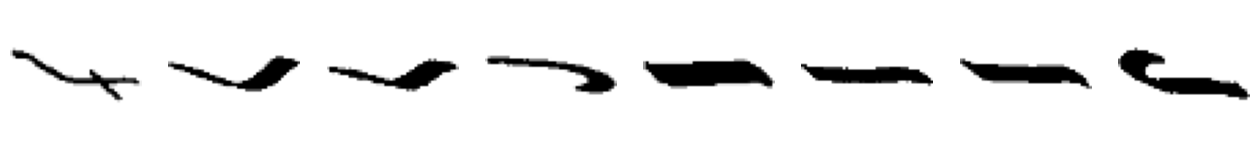

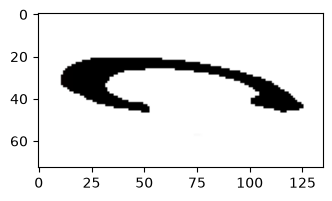

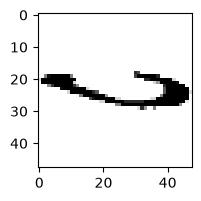

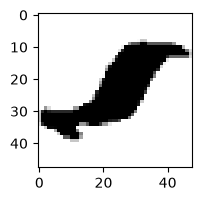

In [6]:
sample = train_data.sample(8, random_state=0)
fig, axes = plt.subplots(1, 8, figsize=(16, 2))
for k in range(8):
  axes[k].imshow(Image.open(sample['Path'].iloc[k]), cmap='gray')
  axes[k].axis('off')
plt.show()

for p in test_data['datapointID'][:3]:          # a few test sequences
  plt.figure(figsize=(12, 2))
  plt.imshow(Image.open(p), cmap='gray')
  plt.show()

# preprocessing

In [7]:
SIZE = 48

def to_ink(img):
    return 1 - np.array(img.convert('L')) / 255.0    

def centercrop(ink, a, b):
    piece = ink[:, a:b]
    rows = np.where((piece > 0.5).any(axis=1))[0]
    cols = np.where((piece > 0.5).any(axis=0))[0]
    if len(rows)==0:
        return np.zeros((SIZE, SIZE))
    piece = piece[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1] 
    h, w = piece.shape
    side = max(h, w)
    square = np.zeros((side, side))
    top = (side-h)//2
    left = (side-w)//2
    square[top:top + h, left:left + w] = piece 
    img = Image.fromarray((square*255).astype(np.uint8)).resize((SIZE, SIZE))
    return np.array(img) / 255.0
    
def segmentsequence(path, min_area=15):
    ink = to_ink(Image.open(path))
    labels = measure.label(ink > 0.5)               
    blobs = []
    for r in measure.regionprops(labels):
        if r.area >= min_area:                      
            minr, minc, maxr, maxc = r.bbox
            blobs.append([minc, maxc, r.label])
    blobs.sort()                                    

    symbols = []                                   
    for left, right, lab in blobs:
        if len(symbols) > 0:
            prev = symbols[-1]
            prev_center = (prev[0] + prev[1]) / 2
            center = (left + right) / 2
            if left < prev_center or center < prev[1]:   
                prev[1] = max(prev[1], right)
                prev[2].append(lab)
                continue
        symbols.append([left, right, [lab]])

    crops = []
    for left, right, labs in symbols:
        keep = np.isin(labels, labs)                
        crops.append(centercrop(ink * keep, left, right))
    return crops        


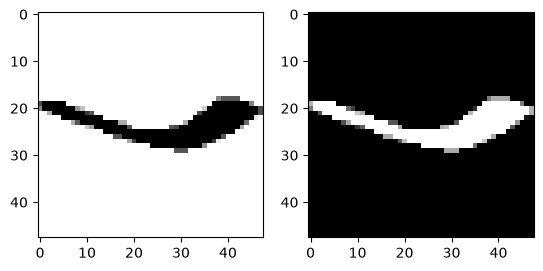

In [8]:
img = Image.open(train_data['Path'].iloc[1])
plt.subplot(1, 2, 1); plt.imshow(img, cmap='gray')
plt.subplot(1, 2, 2); plt.imshow(to_ink(img), cmap='gray')
plt.show()

In [9]:
imagini = []
for p in train_data['Path']:
    ink = to_ink(Image.open(p))
    imagini.append(centercrop(ink, 0, ink.shape[1]).flatten())
X = pd.DataFrame(imagini)
y = train_data['Effect']

# validare

In [10]:
def evaluate(model, X, y):
  kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

  scores = []
  for fit_rows, val_rows in kf.split(X, y):
    X_fit = X.iloc[fit_rows]
    y_fit = y.iloc[fit_rows]
    X_val = X.iloc[val_rows]
    y_val = y.iloc[val_rows]

    model.fit(X_fit, y_fit)
    preds = model.predict(X_val)
    score = accuracy_score(y_val, preds)

    scores.append(score)
  return np.mean(scores)

In [11]:
# model

In [12]:
print(evaluate(DummyClassifier(strategy='most_frequent'), X, y))
print(evaluate(KNeighborsClassifier(n_neighbors=3), X, y))

0.2091508892713712
0.9616179001721171


In [ ]:
model = KNeighborsClassifier(n_neighbors=3).fit(X, y)

def valefect(label):
  if label in ('A', 'B'):
    return 0                                    
  return int(label)


answers = []
for p in test_data['datapointID']:
    crops = segmentsequence(p)
    if len(crops) == 0:
        answers.append('0')
    else:
        topredict = []
        for c in crops:
            topredict.append(c.flatten())
        topredict = pd.DataFrame(topredict)

        preds = model.predict(topredict)
        total = 0
        seq = []
        for lab in preds:
            total += valefect(lab)
            seq.append(str(total))
        answers.append('|'.join(seq))

submission = pd.DataFrame({'subtaskID': 1, 'datapointID': test_data['datapointID'], 'answer': answers})
submission.to_csv('output.csv', index=False)